# Sales Performance Analysis

An exploratory analysis of retail sales, profitability and customer behavior using Python.

## 1. Project Setup

Importing libraries and loading the dataset.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"

df = pd.read_csv(url)

df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [ ]:
print("Размер таблицы:", df.shape)

print("\nТипы данных:")
print(df.dtypes)

print("\nПропущенные значения:")
print(df.isnull().sum())

print("\nСтатистика:")
display(df.describe())

Размер таблицы: (244, 7)

Типы данных:
total_bill    float64
tip           float64
sex            object
smoker         object
day            object
time           object
size            int64
dtype: object

Пропущенные значения:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

Статистика:


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [ ]:
from google.colab import files

uploaded = files.upload()


Saving Sample - Superstore.csv to Sample - Superstore (1).csv


In [ ]:
df = pd.read_csv("Sample - Superstore.csv", encoding="latin1")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 2. Data Exploration

Understanding dataset structure, columns, data types and basic statistics.


In [ ]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (9994, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Data types:
Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

Missing values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name   

## 3. Data Quality Inspection

Checking missing values, duplicate records, unique customers and orders.

In [ ]:
# 1. Check missing values
# We need to identify empty cells because they can affect calculations.

missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values[missing_values > 0])


# 2. Check duplicate rows
# Duplicate records may lead to incorrect sales calculations.

print("\nDuplicate rows:", df.duplicated().sum())


# 3. Count unique customers and orders
# This helps us understand the size of our customer base.

print("\nUnique customers:", df["Customer ID"].nunique())
print("Unique orders:", df["Order ID"].nunique())


# 4. Check the period covered by the dataset
# This tells us which time period our analysis will cover.

df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

print("\nOrder date range:")
print(df["Order Date"].min(), "-", df["Order Date"].max())

Missing values:
Series([], dtype: int64)

Duplicate rows: 0

Unique customers: 793
Unique orders: 5009

Order date range:
2014-01-03 00:00:00 - 2017-12-30 00:00:00


# New section## 4. Data Cleaning

Checking numerical values, identifying unusual records and preparing the dataset for further analysis.

In [ ]:
# Check numerical columns for unusual values

print("Sales statistics:")
display(df["Sales"].describe())

print("\nProfit statistics:")
display(df["Profit"].describe())

print("\nQuantity statistics:")
display(df["Quantity"].describe())

# Identify transactions with negative profit
negative_profit = df[df["Profit"] < 0]

print("\nRows with negative profit:", len(negative_profit))

# Identify transactions with negative sales
negative_sales = df[df["Sales"] < 0]

print("Rows with negative sales:", len(negative_sales))

Sales statistics:


,Sales
count,9994.000000
mean,229.858001
std,623.245101
min,0.444000
25%,17.280000
50%,54.490000
75%,209.940000
max,22638.480000



Profit statistics:


,Profit
count,9994.000000
mean,28.656896
std,234.260108
min,-6599.978000
25%,1.728750
50%,8.666500
75%,29.364000
max,8399.976000



Quantity statistics:


,Quantity
count,9994.000000
mean,3.789574
std,2.225110
min,1.000000
25%,2.000000
50%,3.000000
75%,5.000000
max,14.000000



Rows with negative profit: 1871
Rows with negative sales: 0


### Initial Data Observations
- Average sales per record are significantly higher than median sales.
- The sales distribution appears to be right-skewed.
- Profit values include both positive and negative transactions.
- Some transactions generate substantial losses, requiring further investigation.

In [ ]:
# Calculate the number of profitable and unprofitable transactions

profitable_transactions = df[df["Profit"] > 0]
unprofitable_transactions = df[df["Profit"] < 0]

print("Profitable transactions:", len(profitable_transactions))
print("Unprofitable transactions:", len(unprofitable_transactions))

# Calculate the percentage of unprofitable transactions

loss_percentage = (
    len(unprofitable_transactions) / len(df) * 100
)

print(f"Unprofitable transactions: {loss_percentage:.2f}%")

Profitable transactions: 8058
Unprofitable transactions: 1871
Unprofitable transactions: 18.72%


### Profitability Overview

- 8,058 records generated positive profit.
- 1,871 records resulted in a financial loss.
- 18.72% of all records were unprofitable.
- 65 records generated zero profit.

Further analysis is required to identify the categories and regions associated with financial losses.

## 5. Exploratory Data Analysis (EDA)

Exploring sales and profitability patterns across product categories, regions and customer segments.

In [ ]:
# Calculate sales and profit by product category

category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit=("Profit", "mean"),
    Total_Orders=("Order ID", "nunique")
).sort_values(by="Total_Sales", ascending=False)

# Display the results
display(category_analysis.round(2))

,Total_Sales,Total_Profit,Average_Profit,Total_Orders
Category,,,,
Technology,836154.03,145454.95,78.75,1544
Furniture,741999.80,18451.27,8.70,1764
Office Supplies,719047.03,122490.80,20.33,3742


### Sales Performance by Product Category

Comparing total revenue across product categories to identify the main sales drivers.

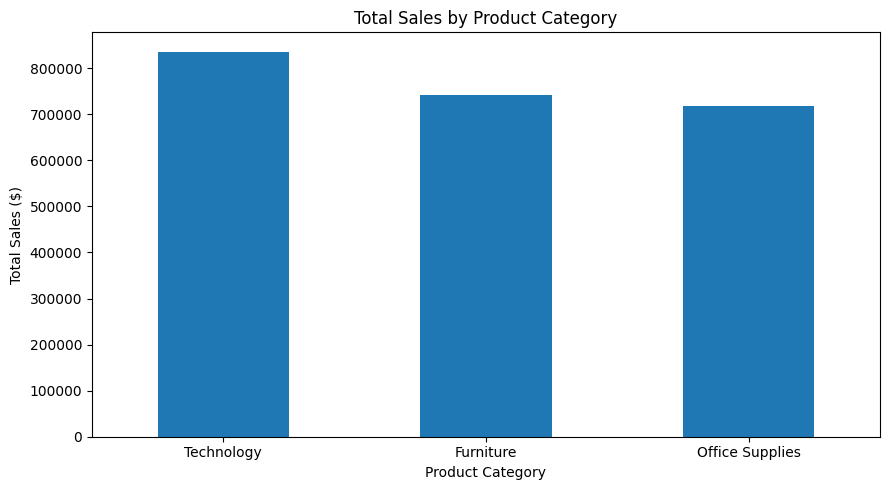

In [ ]:
# Visualize total sales by product category

plt.figure(figsize=(9, 5))

category_analysis["Total_Sales"].plot(
    kind="bar",
    title="Total Sales by Product Category"
)

plt.xlabel("Product Category")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

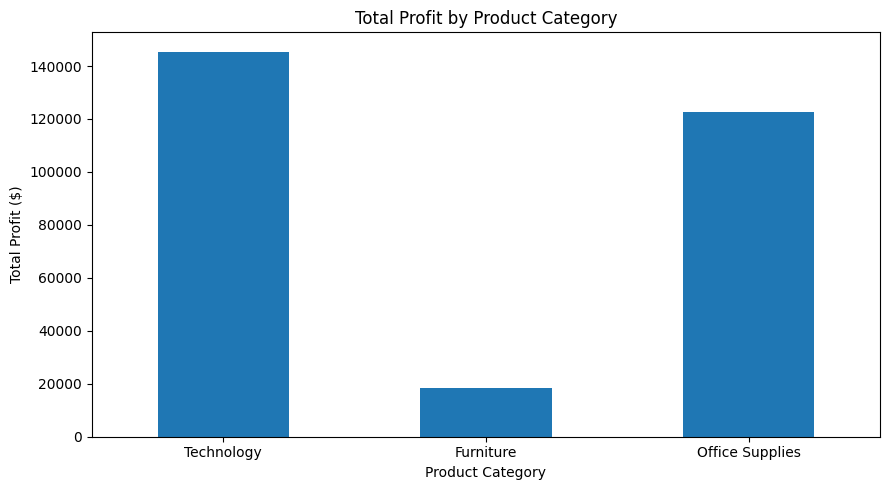

In [ ]:
# Visualize total profit by product category

plt.figure(figsize=(9, 5))

category_analysis["Total_Profit"].plot(
    kind="bar",
    title="Total Profit by Product Category"
)

plt.xlabel("Product Category")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Profit Margin Analysis

Calculating profit margins across product categories to evaluate sales efficiency and identify less profitable business areas.

In [ ]:
# Calculate profit margin for each product category

category_analysis["Profit_Margin"] = (
    category_analysis["Total_Profit"] /
    category_analysis["Total_Sales"] * 100
)

# Sort categories by profit margin
category_analysis = category_analysis.sort_values(
    by="Profit_Margin",
    ascending=False
)

display(category_analysis.round(2))

,Total_Sales,Total_Profit,Average_Profit,Total_Orders,Profit_Margin
Category,,,,,
Technology,836154.03,145454.95,78.75,1544,17.40
Office Supplies,719047.03,122490.80,20.33,3742,17.04
Furniture,741999.80,18451.27,8.70,1764,2.49


### Business Insights — Product Category Analysis

1. Technology generated the highest total sales ($836,154) and total profit ($145,455).

2. Technology also achieved the highest profit margin (17.40%), slightly outperforming Office Supplies (17.04%).

3. Furniture generated $741,999 in sales but only $18,451 in profit.

4. Furniture has a significantly lower profit margin (2.49%), indicating potential profitability issues.

Recommendation:
The company should investigate Furniture pricing, discount strategies and operational costs to improve profitability.

## 6. Regional Sales and Profit Analysis

Analyzing sales performance and profitability across different geographical regions to identify strong and underperforming markets.

In [ ]:
# Calculate sales and profit by region

region_analysis = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
)

# Calculate profit margin
region_analysis["Profit_Margin"] = (
    region_analysis["Total_Profit"] /
    region_analysis["Total_Sales"] * 100
)

# Sort regions by total profit
region_analysis = region_analysis.sort_values(
    by="Total_Profit",
    ascending=False
)

display(region_analysis.round(2))

,Total_Sales,Total_Profit,Total_Orders,Profit_Margin
Region,,,,
West,725457.82,108418.45,1611,14.94
East,678781.24,91522.78,1401,13.48
South,391721.90,46749.43,822,11.93
Central,501239.89,39706.36,1175,7.92


### Business Insights — Regional Analysis

1. The West region generated the highest total profit.
2. The Central region demonstrated the lowest total profit.
3. All regions generated positive overall profit.
4. Regional performance varies, suggesting opportunities to improve sales and profitability in weaker markets.

Recommendation:
Investigate the factors behind the performance gap between the West and Central regions.

## 7. Product Sub-Category Analysis

Analyzing product sub-categories to identify the most profitable products and potential sources of financial losses.

In [ ]:
# Calculate sales and profit by product sub-category

subcategory_analysis = df.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit=("Profit", "mean")
)

# Calculate profit margin
subcategory_analysis["Profit_Margin"] = (
    subcategory_analysis["Total_Profit"] /
    subcategory_analysis["Total_Sales"] * 100
)

# Sort by total profit
subcategory_analysis = subcategory_analysis.sort_values(
    by="Total_Profit",
    ascending=True
)

display(subcategory_analysis.round(2))

,Total_Sales,Total_Profit,Average_Profit,Profit_Margin
Sub-Category,,,,
Tables,206965.53,-17725.48,-55.57,-8.56
Bookcases,114880.00,-3472.56,-15.23,-3.02
Supplies,46673.54,-1189.10,-6.26,-2.55
Fasteners,3024.28,949.52,4.38,31.40
Machines,189238.63,3384.76,29.43,1.79
Labels,12486.31,5546.25,15.24,44.42
Art,27118.79,6527.79,8.20,24.07
Envelopes,16476.40,6964.18,27.42,42.27
Furnishings,91705.16,13059.14,13.65,14.24


### Business Insights — Product Sub-Category Analysis

1. Copiers generated the highest total profit ($55,617.82).

2. Tables generated the largest financial loss (-$17,725.48).

3. Bookcases and Supplies also demonstrated negative profitability.

4. Labels achieved the highest profit margin (44.42%), despite having relatively low total sales.

Recommendation:
Investigate discount policies and pricing strategies for Tables, Bookcases and Supplies to identify the causes of negative profitability.

## 8. Discount and Profitability Analysis

Investigating the relationship between discount levels and profitability to identify whether excessive discounts contribute to financial losses.

In [ ]:
# Calculate average discount for profitable and unprofitable transactions

discount_analysis = df.groupby(
    df["Profit"] < 0
).agg(
    Average_Discount=("Discount", "mean"),
    Average_Profit=("Profit", "mean"),
    Transaction_Count=("Profit", "count")
)

# Rename index for better readability
discount_analysis.index = [
    "Profitable",
    "Unprofitable"
]

display(discount_analysis.round(3))

,Average_Discount,Average_Profit,Transaction_Count
Profitable,0.081,54.478,8123
Unprofitable,0.481,-83.448,1871


### Business Insights — Discount Analysis

1. Profitable transactions had an average discount of 8.1%.

2. Unprofitable transactions had an average discount of 48.1%.

3. The average profit was $54.48 for profitable transactions and -$83.45 for unprofitable transactions.

4. High discount levels are strongly associated with negative profitability.

Recommendation:
Review discount policies and establish appropriate discount limits based on product profitability.

## 9. Discount Impact Analysis

Analyzing profitability across different discount levels to identify potential discount thresholds associated with financial losses.

In [ ]:
# Group transactions by discount level

discount_levels = df.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit=("Profit", "mean"),
    Transaction_Count=("Profit", "count")
)

display(discount_levels.round(2))

,Total_Sales,Total_Profit,Average_Profit,Transaction_Count
Discount,,,,
0.00,1087908.47,320987.60,66.90,4798
0.10,54369.35,9029.18,96.06,94
0.15,27558.52,1418.99,27.29,52
0.20,764594.37,90337.31,24.70,3657
0.30,103226.66,-10369.28,-45.68,227
0.32,14493.46,-2391.14,-88.56,27
0.40,116417.78,-23057.05,-111.93,206
0.45,5484.97,-2493.11,-226.65,11
0.50,58918.54,-20506.43,-310.70,66


### Business Insights — Discount Impact Analysis

1. Transactions with discounts of 0%, 10%, 15% and 20% generated positive total profit.

2. Transactions with discounts of 30% or higher generated negative total profit.

3. The 70% discount group generated the largest total loss (-$40,075.36).

4. High discount levels are associated with significantly lower profitability.

Recommendation:
The company should review its discount policy and evaluate profitability before offering large discounts.

Note:
These findings show an association, not proof of causation. Product category and transaction volume should also be considered.

### Profitability Across Discount Levels

Visualizing total and average profit across different discount levels to identify potentially unprofitable pricing strategies.

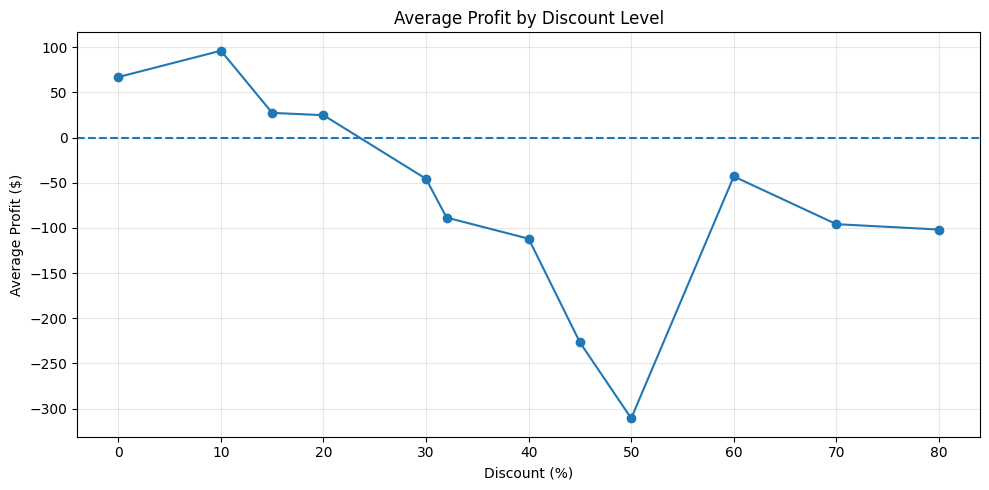

In [ ]:
# Visualize average profit by discount level

plt.figure(figsize=(10, 5))

plt.plot(
    discount_levels.index * 100,
    discount_levels["Average_Profit"],
    marker="o"
)

plt.axhline(y=0, linestyle="--")

plt.title("Average Profit by Discount Level")
plt.xlabel("Discount (%)")
plt.ylabel("Average Profit ($)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Category Profitability by Discount

Analyzing the relationship between discount levels and profitability across product categories to identify which categories are most sensitive to discounts.

In [ ]:
# Group data by product category and discount level

category_discount_analysis = df.groupby(
    ["Category", "Discount"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit=("Profit", "mean"),
    Transaction_Count=("Profit", "count")
).reset_index()

# Calculate profit margin
category_discount_analysis["Profit_Margin"] = (
    category_discount_analysis["Total_Profit"] /
    category_discount_analysis["Total_Sales"] * 100
)

# Sort results by category and discount
category_discount_analysis = category_discount_analysis.sort_values(
    ["Category", "Discount"]
)

display(category_discount_analysis.round(2))

,Category,Discount,Total_Sales,Total_Profit,Average_Profit,Transaction_Count,Profit_Margin
0,Furniture,0.00,256025.27,58133.08,69.54,836,22.71
1,Furniture,0.10,46634.25,7111.01,93.57,76,15.25
2,Furniture,0.15,27558.52,1418.99,27.29,52,5.15
3,Furniture,0.20,216631.02,6265.95,10.19,615,2.89
4,Furniture,0.30,99470.35,-10695.32,-48.18,222,-10.75
5,Furniture,0.32,14493.46,-2391.14,-88.56,27,-16.50
6,Furniture,0.40,45614.41,-16187.40,-215.83,75,-35.49
7,Furniture,0.45,5484.97,-2493.11,-226.65,11,-45.45
8,Furniture,0.50,20983.47,-12871.20,-238.36,54,-61.34
9,Furniture,0.60,6644.70,-5944.66,-43.08,138,-89.46


### Average Profit by Category and Discount

Comparing average profit across discount levels for each product category.

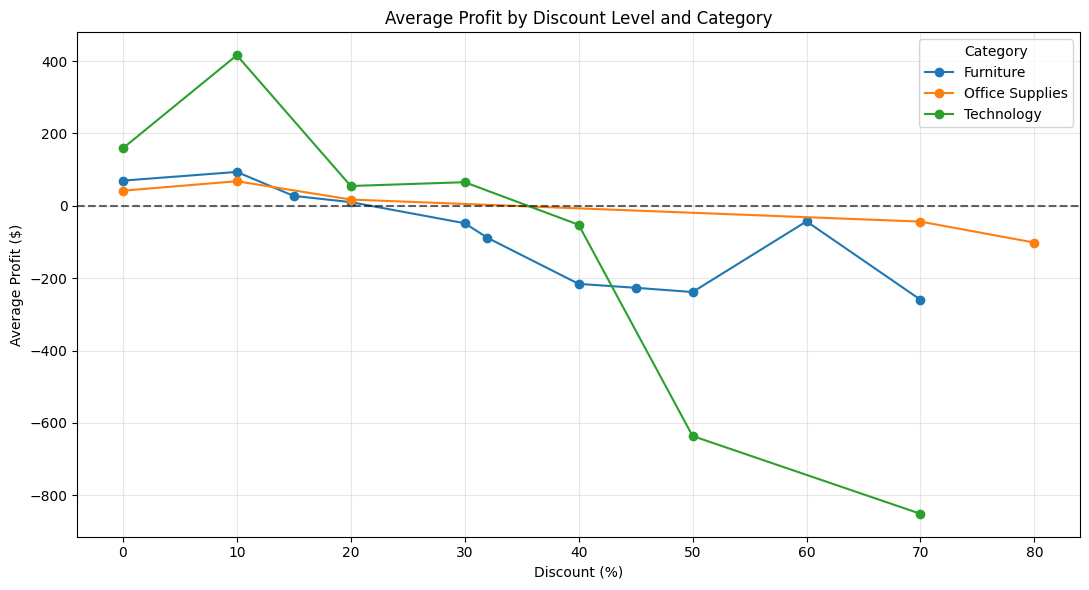

In [ ]:
# Plot average profit by discount level for each category

plt.figure(figsize=(11, 6))

for category in category_discount_analysis["Category"].unique():

    category_data = category_discount_analysis[
        category_discount_analysis["Category"] == category
    ]

    plt.plot(
        category_data["Discount"] * 100,
        category_data["Average_Profit"],
        marker="o",
        label=category
    )

plt.axhline(y=0, linestyle="--", color="black", alpha=0.6)

plt.title("Average Profit by Discount Level and Category")
plt.xlabel("Discount (%)")
plt.ylabel("Average Profit ($)")
plt.legend(title="Category")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Business Insights — Category Discount Analysis

1. Furniture becomes unprofitable at a 30% discount level.

2. Office Supplies maintains positive average profitability at discount levels up to 20%, but generates losses at 70% and 80%.

3. Technology experiences negative average profitability starting at a 40% discount level.

4. Furniture appears particularly sensitive to discount increases.

Recommendation:
Implement category-specific discount strategies instead of applying uniform discount policies across all product categories.

Note:
Some discount groups contain very few transactions. Conclusions should be interpreted with caution.

## 11. Transaction Volume Analysis

Evaluating the number of transactions at each discount level to assess the reliability of profitability comparisons.

In [ ]:
# Analyze transaction volume by category and discount

transaction_volume = category_discount_analysis.pivot(
    index="Discount",
    columns="Category",
    values="Transaction_Count"
)

display(transaction_volume.fillna(0).astype(int))

Category,Furniture,Office Supplies,Technology
Discount,,,
0.00,836,3129,833
0.10,76,16,2
0.15,52,0,0
0.20,615,2201,841
0.30,222,0,5
0.32,27,0,0
0.40,75,0,131
0.45,11,0,0
0.50,54,0,12


### Business Insights — Transaction Volume Analysis

1. Furniture has 222 transactions at a 30% discount, with negative average profit.

2. Office Supplies has substantial transaction volumes at 70% and 80% discounts, with negative profitability.

3. Technology has 131 transactions at a 40% discount, showing negative average profit.

4. Some discount groups have very small sample sizes, which limits the reliability of conclusions.

Recommendation:
Prioritize discount policy reviews for groups with both high transaction volumes and negative profitability.

## 12. Customer Analysis

Analyzing customer purchasing behavior, sales contribution and profitability to identify valuable customers and potential loss-making accounts.

In [ ]:
# Calculate sales and profit by customer

customer_analysis = df.groupby(
    ["Customer ID", "Customer Name"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Average_Discount=("Discount", "mean")
)

# Identify the top 10 customers by total sales
top_customers = customer_analysis.sort_values(
    by="Total_Sales",
    ascending=False
).head(10)

display(top_customers.round(2))

,,Total_Sales,Total_Profit,Total_Orders,Average_Discount
Customer ID,Customer Name,,,,
SM-20320,Sean Miller,25043.05,-1980.74,5,0.25
TC-20980,Tamara Chand,19052.22,8981.32,5,0.12
RB-19360,Raymond Buch,15117.34,6976.10,6,0.09
TA-21385,Tom Ashbrook,14595.62,4703.79,4,0.08
AB-10105,Adrian Barton,14473.57,5444.81,10,0.24
KL-16645,Ken Lonsdale,14175.23,806.86,12,0.20
SC-20095,Sanjit Chand,14142.33,5757.41,9,0.06
HL-15040,Hunter Lopez,12873.30,5622.43,6,0.02
SE-20110,Sanjit Engle,12209.44,2650.68,11,0.11


In [ ]:
# Identify the top 10 customers by total profit

top_profit_customers = customer_analysis.sort_values(
    by="Total_Profit",
    ascending=False
).head(10)

display(top_profit_customers.round(2))

,,Total_Sales,Total_Profit,Total_Orders,Average_Discount
Customer ID,Customer Name,,,,
TC-20980,Tamara Chand,19052.22,8981.32,5,0.12
RB-19360,Raymond Buch,15117.34,6976.10,6,0.09
SC-20095,Sanjit Chand,14142.33,5757.41,9,0.06
HL-15040,Hunter Lopez,12873.30,5622.43,6,0.02
AB-10105,Adrian Barton,14473.57,5444.81,10,0.24
TA-21385,Tom Ashbrook,14595.62,4703.79,4,0.08
CM-12385,Christopher Martinez,8954.02,3899.89,4,0.12
KD-16495,Keith Dawkins,8181.26,3038.63,12,0.09
AR-10540,Andy Reiter,6608.45,2884.62,6,0.07


In [ ]:
# Identify the 10 customers with the lowest total profit

worst_customers = customer_analysis.sort_values(
    by="Total_Profit",
    ascending=True
).head(10)

display(worst_customers.round(2))

,,Total_Sales,Total_Profit,Total_Orders,Average_Discount
Customer ID,Customer Name,,,,
CS-12505,Cindy Stewart,5690.05,-6626.39,6,0.20
GT-14635,Grant Thornton,9351.21,-4108.66,3,0.25
LF-17185,Luke Foster,3930.51,-3583.98,7,0.32
SR-20425,Sharelle Roach,3233.48,-3333.91,5,0.37
HG-14965,Henry Goldwyn,3247.64,-2797.96,12,0.17
NC-18415,Nathan Cano,2218.99,-2204.81,6,0.26
SB-20290,Sean Braxton,8057.89,-2082.75,7,0.24
SM-20320,Sean Miller,25043.05,-1980.74,5,0.25
CP-12340,Christine Phan,5888.28,-1850.30,8,0.21


### Business Insights — Customer Analysis

1. Sean Miller generated the highest total sales ($25,043.05), but resulted in a total loss of $1,980.74.

2. Tamara Chand generated the highest total profit ($8,981.32), demonstrating that the highest-revenue customer is not necessarily the most profitable.

3. Cindy Stewart generated the largest customer-level loss (-$6,626.39).

4. Customer profitability varies significantly, highlighting the importance of analyzing profit rather than revenue alone.

Recommendation:
Investigate loss-making customer transactions, focusing on product mix, discount levels and order profitability.

## 13. Sales Trends Analysis

Analyzing historical sales and profit trends over time to identify business growth patterns and seasonal variations.

In [ ]:
# Extract year and month from order dates

df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month

# Create a year-month column

df["Year_Month"] = df["Order Date"].dt.to_period("M")

print("Available years:")
print(sorted(df["Year"].unique()))

print("\nAvailable months:")
print(sorted(df["Month"].unique()))

Available years:
[np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017)]

Available months:
[np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]


In [ ]:
# Calculate monthly sales and profit

monthly_sales = df.groupby("Year_Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
)

display(monthly_sales.head(12).round(2))

,Total_Sales,Total_Profit,Total_Orders
Year_Month,,,
2014-01,14236.90,2450.19,32
2014-02,4519.89,862.31,28
2014-03,55691.01,498.73,71
2014-04,28295.34,3488.84,66
2014-05,23648.29,2738.71,69
2014-06,34595.13,4976.52,66
2014-07,33946.39,-841.48,65
2014-08,27909.47,5318.10,72
2014-09,81777.35,8328.10,130


### Monthly Sales Trend

Visualizing monthly revenue to identify sales growth, fluctuations and seasonal patterns.

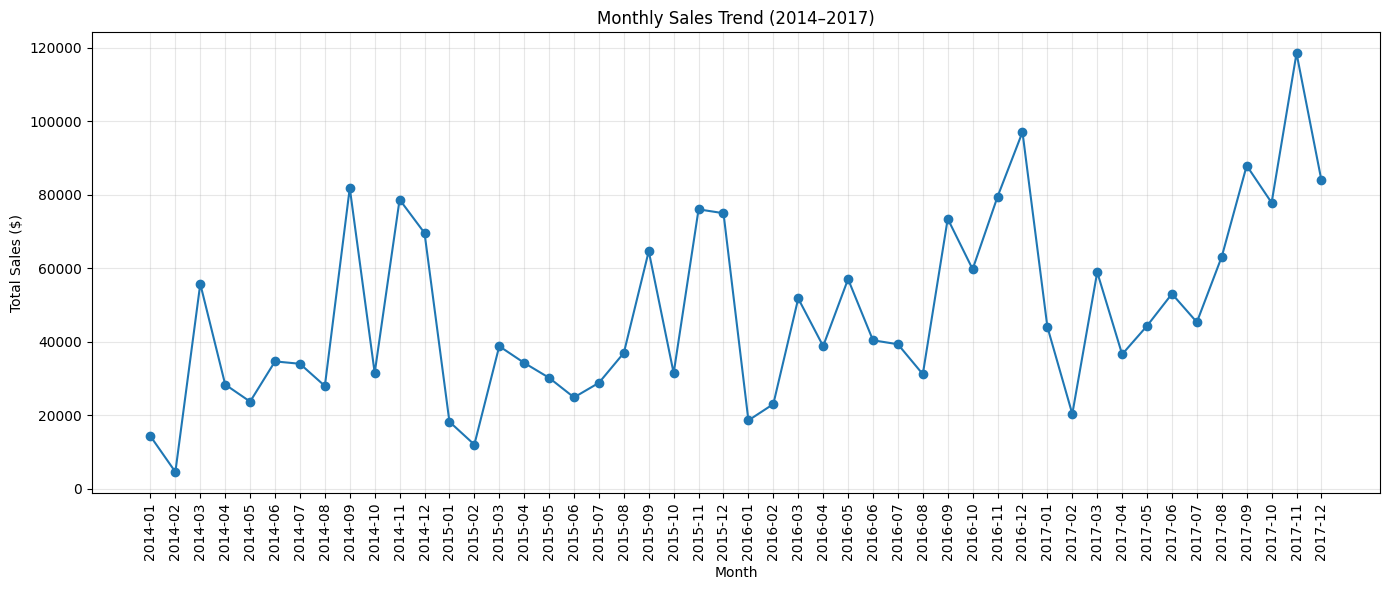

In [ ]:
# Visualize monthly sales trends

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend (2014–2017)")
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=90)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Business Insights — Monthly Sales Trends

1. Monthly sales show an overall upward trend between 2014 and 2017.

2. Significant sales peaks occurred in September 2014, December 2016 and November 2017.

3. Monthly revenue fluctuates considerably, indicating potential seasonal patterns.

4. November and December appear to be important sales periods, requiring further investigation.

Further analysis:
Compare annual revenue and average monthly sales to confirm business growth and identify seasonal patterns.

### Annual Sales Performance

Comparing yearly revenue and profitability to evaluate long-term business growth.

In [ ]:
# Calculate annual sales and profit

annual_analysis = df.groupby("Year").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
)

# Calculate year-over-year sales growth

annual_analysis["Sales_Growth_%"] = (
    annual_analysis["Total_Sales"].pct_change() * 100
)

display(annual_analysis.round(2))

,Total_Sales,Total_Profit,Total_Orders,Sales_Growth_%
Year,,,,
2014,484247.50,49543.97,969,NaN
2015,470532.51,61618.60,1038,-2.83
2016,609205.60,81795.17,1315,29.47
2017,733215.26,93439.27,1687,20.36


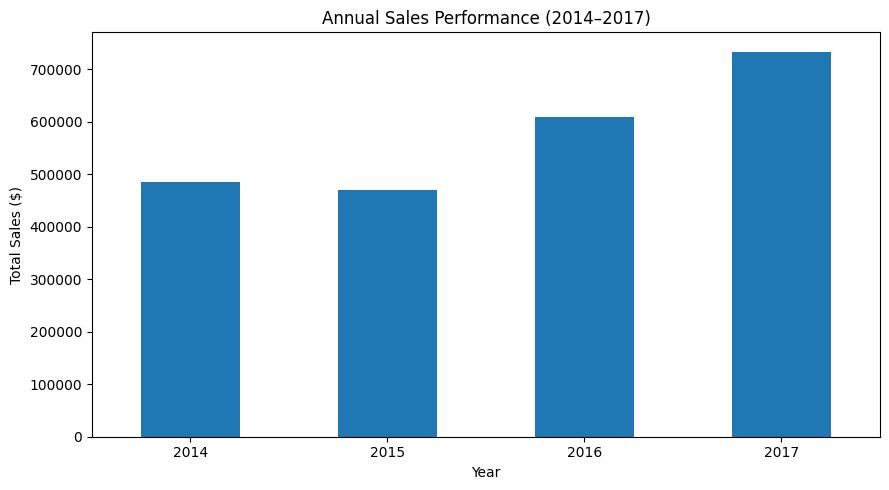

In [ ]:
# Visualize annual sales performance

plt.figure(figsize=(9, 5))

annual_analysis["Total_Sales"].plot(
    kind="bar",
    title="Annual Sales Performance (2014–2017)"
)

plt.xlabel("Year")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Business Insights — Annual Sales Performance

1. 2017 was the strongest year, generating $733,215.26 in revenue.

2. Sales declined by 2.83% in 2015 compared to 2014.

3. The highest annual sales growth occurred in 2016, reaching 29.47%.

4. Revenue increased significantly in both 2016 and 2017.

5. Annual profit increased consistently throughout the four-year period.

Recommendation:
Continue investigating the factors behind revenue and profit growth, particularly the strong performance in 2016 and 2017.

### Annual Profitability Analysis

Evaluating yearly profit margins to understand whether revenue growth translates into improved business profitability.

In [ ]:
# Calculate annual profit margin

annual_analysis["Profit_Margin"] = (
    annual_analysis["Total_Profit"] /
    annual_analysis["Total_Sales"] * 100
)

# Display annual profitability metrics

display(
    annual_analysis[
        ["Total_Sales", "Total_Profit", "Profit_Margin"]
    ].round(2)
)

,Total_Sales,Total_Profit,Profit_Margin
Year,,,
2014,484247.50,49543.97,10.23
2015,470532.51,61618.60,13.10
2016,609205.60,81795.17,13.43
2017,733215.26,93439.27,12.74


### Business Insights — Annual Profitability Analysis

1. Profit margin improved from 10.23% in 2014 to 13.43% in 2016.

2. 2016 achieved the highest annual profit margin.

3. Despite generating the highest revenue in 2017, the company experienced a decline in profit margin to 12.74%.

4. Revenue growth does not necessarily translate into improved profitability.

Recommendation:
Monitor both revenue growth and profit margins to ensure that business expansion remains profitable.

## 14. Shipping Analysis

Analyzing shipping methods, delivery time and their relationship with sales and profitability to identify operational improvement opportunities.

In [ ]:
# Analyze sales and profit by shipping mode

shipping_analysis = df.groupby("Ship Mode").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Average_Profit=("Profit", "mean")
)

display(shipping_analysis.round(2))

,Total_Sales,Total_Profit,Total_Orders,Average_Profit
Ship Mode,,,,
First Class,351428.42,48969.84,787,31.84
Same Day,128363.12,15891.76,264,29.27
Second Class,459193.57,57446.64,964,29.54
Standard Class,1358215.74,164088.79,2994,27.49


In [ ]:
# Calculate delivery time in days

df["Delivery_Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

# Analyze delivery time by shipping mode

delivery_analysis = df.groupby("Ship Mode").agg(
    Average_Delivery_Days=("Delivery_Days", "mean"),
    Min_Delivery_Days=("Delivery_Days", "min"),
    Max_Delivery_Days=("Delivery_Days", "max")
)

display(delivery_analysis.round(2))

,Average_Delivery_Days,Min_Delivery_Days,Max_Delivery_Days
Ship Mode,,,
First Class,2.18,1,4
Same Day,0.04,0,1
Second Class,3.24,1,5
Standard Class,5.01,3,7


### Business Insights — Shipping Analysis

1. Standard Class accounts for the highest sales and total profit due to its large transaction volume.

2. Same Day shipping has the shortest average processing time of 0.04 days.

3. Standard Class has the longest average processing time of 5.01 days.

4. First Class generates the highest average profit per transaction among shipping methods.

Recommendation:
Maintain Standard Class as the primary shipping option while evaluating opportunities to improve processing efficiency and promote faster shipping options.

### Shipping Efficiency and Profitability

Comparing average profit per transaction with average shipping processing time across different shipping methods.

In [ ]:
# Combine shipping profitability and delivery time

shipping_comparison = shipping_analysis[
    ["Average_Profit"]
].join(
    delivery_analysis[["Average_Delivery_Days"]]
)

display(shipping_comparison.round(2))

,Average_Profit,Average_Delivery_Days
Ship Mode,,
First Class,31.84,2.18
Same Day,29.27,0.04
Second Class,29.54,3.24
Standard Class,27.49,5.01


### Business Insights — Shipping Efficiency and Profitability

1. First Class generates the highest average profit per transaction ($31.84).

2. Same Day provides the fastest order processing time, averaging 0.04 days.

3. Standard Class has the lowest average profit per transaction ($27.49) and the longest processing time (5.01 days).

4. Faster shipping methods do not necessarily generate higher average profits.

Recommendation:
Evaluate shipping methods based on both operational efficiency and profitability rather than delivery speed alone.

# 15. Final Business Insights & Recommendations

Summarizing the key findings from sales, profitability, customer, discount, regional and shipping analyses to provide actionable business recommendations.

In [ ]:
# Calculate overall business KPIs

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()

profit_margin = total_profit / total_sales * 100
average_order_value = total_sales / total_orders

print("KEY BUSINESS METRICS")
print("-" * 35)

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Average Order Value: ${average_order_value:.2f}")

KEY BUSINESS METRICS
-----------------------------------
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5,009
Total Customers: 793
Profit Margin: 12.47%
Average Order Value: $458.61


# Final Business Insights

## Overall Business Performance

The business generated $2.30 million in sales and $286,397 in total profit across 5,009 orders and 793 customers.

The overall profit margin was 12.47%, with an average order value of $458.61.

## Key Findings

1. Technology is the strongest product category in terms of profitability.

2. Furniture experiences significant losses at discount levels of 30% and above.

3. High discount levels are associated with substantial losses across several product categories.

4. Customer profitability varies considerably. High sales revenue does not necessarily indicate high customer profitability.

5. Annual revenue increased significantly between 2015 and 2017.

6. Standard Class is the most frequently used shipping method.

## Business Recommendations

1. Review discount policies, especially for Furniture.

2. Investigate products and customer segments generating negative profits.

3. Monitor profit margins alongside revenue growth.

4. Evaluate shipping performance using both operational and financial metrics.

5. Develop category-specific pricing and discount strategies.

## 16. Order-Level Analysis

Transforming line-item data into order-level data to ensure accurate business metrics and profitability calculations.

In [ ]:
# Aggregate individual product rows into complete orders

order_level = df.groupby("Order ID").agg(
    Customer_ID=("Customer ID", "first"),
    Order_Date=("Order Date", "min"),
    Ship_Date=("Ship Date", "max"),
    Ship_Mode=("Ship Mode", "first"),
    Order_Sales=("Sales", "sum"),
    Order_Profit=("Profit", "sum"),
    Line_Items=("Row ID", "count")
).reset_index()

# Display the first 10 orders

display(order_level.head(10))

,Order ID,Customer_ID,Order_Date,Ship_Date,Ship_Mode,Order_Sales,Order_Profit,Line_Items
0,CA-2014-100006,DK-13375,2014-09-07,2014-09-13,Standard Class,377.970,109.6113,1
1,CA-2014-100090,EB-13705,2014-07-08,2014-07-12,Standard Class,699.192,-19.0890,2
2,CA-2014-100293,NF-18475,2014-03-14,2014-03-18,Standard Class,91.056,31.8696,1
3,CA-2014-100328,JC-15340,2014-01-28,2014-02-03,Standard Class,3.928,1.3257,1
4,CA-2014-100363,JM-15655,2014-04-08,2014-04-15,Standard Class,21.376,7.7192,2
5,CA-2014-100391,BW-11065,2014-05-25,2014-05-29,Standard Class,14.620,6.7252,1
6,CA-2014-100678,KM-16720,2014-04-18,2014-04-22,Standard Class,697.074,61.7937,4
7,CA-2014-100706,LE-16810,2014-12-16,2014-12-18,Second Class,129.440,17.7202,2
8,CA-2014-100762,NG-18355,2014-11-24,2014-11-29,Standard Class,508.620,219.0774,4
9,CA-2014-100860,CS-12505,2014-03-26,2014-03-30,Second Class,18.750,9.0000,1


In [ ]:
# Validate the order-level dataset

print("Original rows:", len(df))
print("Unique orders:", df["Order ID"].nunique())
print("Rows in order-level dataset:", len(order_level))

print("\nAverage line items per order:")
print(round(order_level["Line_Items"].mean(), 2))

print("\nMissing values:")
print(order_level.isnull().sum())

Original rows: 9994
Unique orders: 5009
Rows in order-level dataset: 5009

Average line items per order:
2.0

Missing values:
Order ID        0
Customer_ID     0
Order_Date      0
Ship_Date       0
Ship_Mode       0
Order_Sales     0
Order_Profit    0
Line_Items      0
dtype: int64


In [ ]:
# Analyze shipping performance at order level

shipping_order_analysis = order_level.groupby("Ship_Mode").agg(
    Total_Orders=("Order ID", "count"),
    Total_Sales=("Order_Sales", "sum"),
    Total_Profit=("Order_Profit", "sum"),
    Average_Order_Profit=("Order_Profit", "mean"),
    Average_Order_Value=("Order_Sales", "mean")
)

display(shipping_order_analysis.round(2))

,Total_Orders,Total_Sales,Total_Profit,Average_Order_Profit,Average_Order_Value
Ship_Mode,,,,,
First Class,787,351428.42,48969.84,62.22,446.54
Same Day,264,128363.12,15891.76,60.20,486.22
Second Class,964,459193.57,57446.64,59.59,476.34
Standard Class,2994,1358215.74,164088.79,54.81,453.65


## 17. Customer Profitability Analysis

Analyzing customer-level revenue, profitability and purchasing behavior using aggregated order-level data.

In [ ]:
# Aggregate orders by customer

customer_order_analysis = order_level.groupby(
    "Customer_ID"
).agg(
    Total_Sales=("Order_Sales", "sum"),
    Total_Profit=("Order_Profit", "sum"),
    Total_Orders=("Order ID", "count"),
    Average_Order_Value=("Order_Sales", "mean"),
    Average_Order_Profit=("Order_Profit", "mean")
)

# Identify the top 10 customers by profit

top_customers_by_profit = customer_order_analysis.sort_values(
    by="Total_Profit",
    ascending=False
).head(10)

display(top_customers_by_profit.round(2))

,Total_Sales,Total_Profit,Total_Orders,Average_Order_Value,Average_Order_Profit
Customer_ID,,,,,
TC-20980,19052.22,8981.32,5,3810.44,1796.26
RB-19360,15117.34,6976.10,6,2519.56,1162.68
SC-20095,14142.33,5757.41,9,1571.37,639.71
HL-15040,12873.30,5622.43,6,2145.55,937.07
AB-10105,14473.57,5444.81,10,1447.36,544.48
TA-21385,14595.62,4703.79,4,3648.90,1175.95
CM-12385,8954.02,3899.89,4,2238.50,974.97
KD-16495,8181.26,3038.63,12,681.77,253.22
AR-10540,6608.45,2884.62,6,1101.41,480.77


### Business Insights — Customer Profitability

1. Tamara Chand is the most profitable customer, generating $8,981.32 in total profit across 5 orders.

2. Tamara Chand also has the highest average order value among the top 10 most profitable customers.

3. Raymond Buch ranks second in total customer profitability.

4. Keith Dawkins generated 12 orders but had a relatively low average order profit of $253.22.

5. Customer profitability varies significantly depending on purchasing behavior and order value.

Recommendation:
Focus on customer profitability rather than order frequency alone. Investigate purchasing patterns of highly profitable customers to identify opportunities for customer retention and growth.

### Top 10 Most Profitable Customers

Comparing total customer profit to identify the highest-value customer relationships.

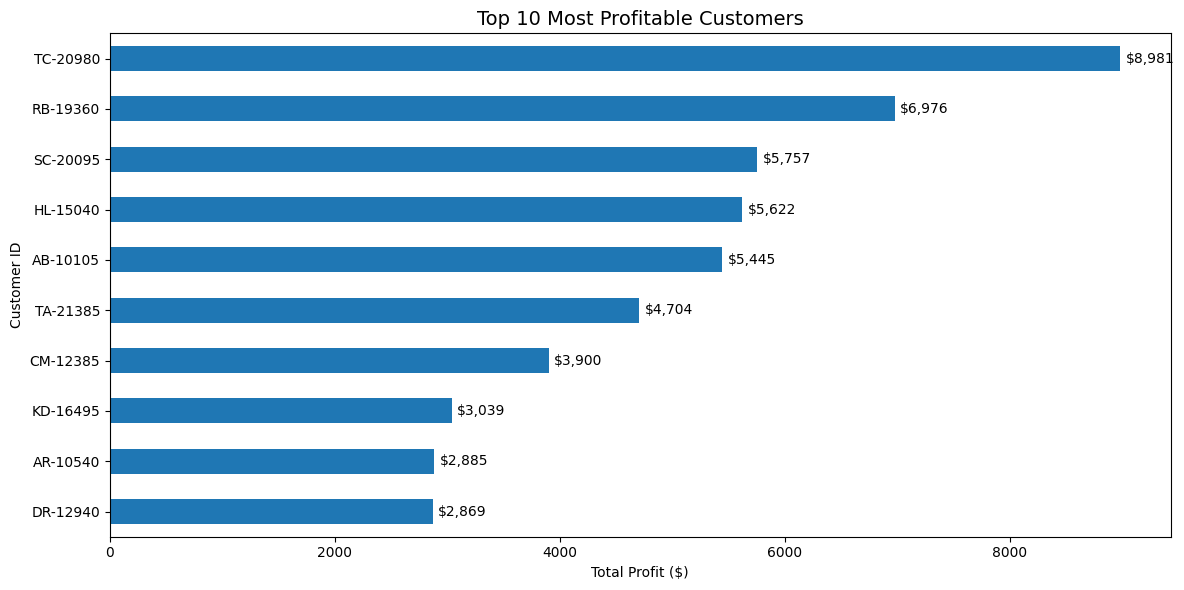

In [ ]:
# Create a more informative customer profitability chart

plt.figure(figsize=(12, 6))

ax = top_customers_by_profit["Total_Profit"].sort_values().plot(
    kind="barh"
)

# Add profit values next to each bar
for bar in ax.patches:
    ax.text(
        bar.get_width() + 50,
        bar.get_y() + bar.get_height() / 2,
        f"${bar.get_width():,.0f}",
        va="center"
    )

plt.title("Top 10 Most Profitable Customers", fontsize=14)
plt.xlabel("Total Profit ($)")
plt.ylabel("Customer ID")

plt.tight_layout()
plt.show()

##Data Export and Power BI Preparation

Preparing clean analytical datasets for business intelligence reporting.

The goal is to export key business metrics and analytical summaries into separate CSV files for further visualization in Power BI.

In [ ]:
# Export the complete cleaned dataset

df.to_csv(
    "superstore_final.csv",
    index=False
)

print("Dataset exported successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Dataset exported successfully!
Rows: 9994
Columns: 25


In [ ]:
from google.colab import files

files.download("superstore_final.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>